# Chambolle-Pock for 2D Image Denoising with ROF and TV-L1 models

In this notebook, we demonstrate the Chambolle-Pock method on 2D image denoising problem.
1. We consider the ROF model used for image deblurring under gaussian noise.
2. We also consider the TV-L1 which is shown to perform better than ROF under outlier salt and peper noise.

In both cases, we apply the method on greyscale images, reproducing some of the results from [1] and also on new test images.

Particularly, we consider the following problem:
- Reimplement the Chambolle-Pock method for the ROF model and TV-L1 model.
- Show results of image denoising under gaussian noise and salt and pepper noise.
- Compare TV-L1 with ROF on salt-and-pepper noise, and analyze the effect of the parameters.

## Problem setup

We use the following test images:
1. The Louvre pyramid, the test image of Figure 4(a) in [1] (500 × 375).
2. The public-domain NASA portrait of the astronaut Eileen Collins that ships with scikit-image, read as grayscale.
  
We add both gaussian noise and salt-and-pepper noise to the test images.

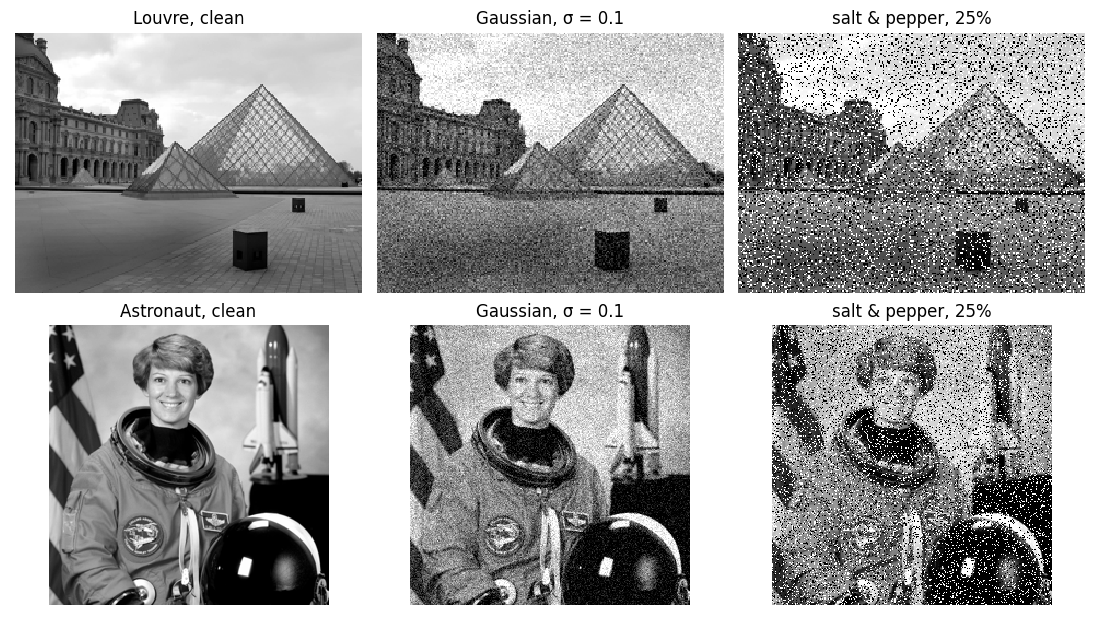

In [1]:
# The test images are in `models/experiments/exp_2d/`: `louvre.png` from Figure 4 of [1] and `astronaut.png` from scikit-image.

%matplotlib widget
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
while not (ROOT / "experiments" / "exp_2d").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]

from cp_image import denoise_image
from experiments.exp_2d.figure import draw_gray_image
from experiments.exp_2d.image import add_noise, image_mse, read_grayscale

IMAGE_DIR = ROOT / "models" / "experiments" / "exp_2d"

SIZE = 192
SEED = 0

# Gaussian: add N(0, σ²) and clip to [0, 1]. Figure 2 of [1] uses σ = 0.1.
# Salt-and-pepper: each pixel becomes 0 or 1, with equal chance, with probability p.
# Figure 4 of [1] uses p = 0.25.
GAUSSIAN_STD = 0.1
FRACTION = 0.25

gallery = {
    "Louvre": read_grayscale(IMAGE_DIR / "louvre.png", 256),
    "Astronaut": read_grayscale(IMAGE_DIR / "astronaut.png", 256),
}

figure, axes = plt.subplots(2, 3, figsize=(11, 6.2))
for row, (name, image) in enumerate(gallery.items()):
    gaussian = add_noise(image, "gaussian", np.random.default_rng(SEED), std=GAUSSIAN_STD)
    pepper = add_noise(image, "salt-and-pepper", np.random.default_rng(SEED), fraction=FRACTION)
    draw_gray_image(axes[row, 0], image, f"{name}, clean")
    draw_gray_image(axes[row, 1], gaussian, f"Gaussian, σ = {GAUSSIAN_STD:g}")
    draw_gray_image(axes[row, 2], pepper, f"salt & pepper, {100 * FRACTION:.0f}%")
figure.tight_layout()
plt.show()


## The Total Variation Problem on a 2D Image

### ROF Model

On a gray image, Chambolle and Pock solve the Rudin–Osher–Fatemi (ROF) problem

$$
\min_u \frac{\lambda}{2}\|u - g\|_2^2 + \|\nabla u\|_1 .
$$

where  $g$ is the noisy image and $u$ is the image we want to recover and $\lambda$ is a parameter that controls the trade-off between the data term and the regularization term. 

1. The Total Variation (TV) Regularizer:
The term $\|\nabla u\|_1$ is the isotropic total variation of the image $u$. It measures the "roughness" of the image by summing the Euclidean length of the gradients between neighboring pixels. Minimizing this term encourages piecewise smooth regions and preserves edges. Unlike the L2 norm, the TV norm is not differentiable at the discontinuities, which makes it more suitable for preserving edges while removing noise.

2. The Data Preservation Term:
The term $\frac{1}{2}\|u - g\|_2^2$ is a quadratic data term that measures the difference between the denoised image $u$ and the noisy image $g$. Minimizing this term ensures that the denoised image is close to the noisy image.

The parameter $\lambda$ controls the trade-off between data fidelity and smoothness. A larger $\lambda$ results in a denoised image closer to the noisy image while a smaller $\lambda$ emphasizes the smoothness of the denoised image.

### TV-L1 Model

The TV-L1 model of [1] keeps the total variation and only changes the data preservation term to L1 norm as well:
$$
\min_u \lambda\|u - g\|_1 + \|\nabla u\|_1 .
$$
As will be shown in the examples, the TV-L1 model is more robust to outliers in the data. Intuitively, this is because the L1 norm is less sensitive to outliers than the L2 norm.


## The pixel grid

The image is an array $u$ with $H$ rows and $W$ columns, and $u_{r,c}$ is the gray value at row $r$ and column $c$. The operator $K$ is the gradient of $u$, taken with forward differences,

$$
(\nabla u)_{r,c} = \bigl(u_{r,c+1} - u_{r,c},\ u_{r+1,c} - u_{r,c}\bigr).
$$

The edge pixels follow the Neumann boundary condition of [1]. (ie, the gradient is 0 at the edges)

The total variation is then,

$$
\mathrm{TV}(u) = \sum_{r,c} |(\nabla u)_{r,c}| = \sum_{r,c} \sqrt{(u_{r,c+1} - u_{r,c})^2 + (u_{r+1,c} - u_{r,c})^2},
$$
for L2 norm and 
$$
\mathrm{TV}(u) = \sum_{r,c} |(\nabla u)_{r,c}| = \sum_{r,c} |u_{r,c+1} - u_{r,c}| + |u_{r+1,c} - u_{r,c}|,
$$
for L1 norm.

The iteration also needs the adjoint $K^* = -\operatorname{div}$, defined by $\langle \nabla u, p\rangle = \langle u, K^*p\rangle$ for $p = (p^1, p^2)$. Writing it out, with entries outside the image counted as 0,

$$
(K^*p)_{r,c} = \bigl(p^1_{r,c-1} - p^1_{r,c}\bigr) + \bigl(p^2_{r-1,c} - p^2_{r,c}\bigr).
$$

Finally, the step sizes need a bound on $\|K\|$. Using $(a-b)^2 \le 2a^2 + 2b^2$, each of the two sums of squared differences is at most $4\|u\|^2$, so

$$
\|\nabla u\|^2 \le 8\,\|u\|^2, \qquad \|K\| \le \sqrt{8}.
$$

This is the same bound as in [1].

In the code, `gradient` and `gradient_adjoint` in `src/cp_image/denoise.py` are these two operators, and `OPERATOR_NORM_BOUND` is $\sqrt{8}$. `denoise_image` passes them to `chambolle_pock` in `src/cp_solver/algorithm.py`. 


## The Chambolle–Pock Iteration

Chambolle and Pock [1] write the ROF/TV-L1 problem as $\min_x F(Kx) + G(x)$. Here, $K$ is the gradient, $G$ is the quadratic data term, and $F$ is the norm inside the total variation.

$F$ and $G$ may be non-smooth but their proximal operators are easy to compute.

We take a primal variable $x$, a dual variable $y$, and an extrapolated primal variable $\bar{x}$. We set $\bar{x}^0 = x^0$. Each iteration then does three updates, and we keep $\theta = 1$.

The dual step reads $\bar{x}$, the value extrapolated at the previous iteration:

$$
y^{n+1} = \operatorname{prox}_{\sigma F^*}\bigl(y^n + \sigma K \bar{x}^n\bigr).
$$

The proximal map is the map of the conjugate $F^*$.

The primal step then updates $x$ with the new dual variable:

$$
x^{n+1} = \operatorname{prox}_{\tau G}\bigl(x^n - \tau K^* y^{n+1}\bigr).
$$

The extrapolation is on $x$. It builds the $\bar{x}$ that the next dual step will read:

$$
\bar{x}^{n+1} = x^{n+1} + \theta \,(x^{n+1} - x^n).
$$

With $\theta = 1$ this is $\bar{x}^{n+1} = 2x^{n+1} - x^n$. The step sizes satisfy $\tau \sigma \|K\|^2 < 1$. We stop when the relative change of $x$ falls below $10^{-5}$, or after 5000 iterations.

The iteration is implemented in  `chambolle_pock` in `src/cp_solver/algorithm.py`. We call it from `denoise_image` in `experiments/exp_2d/denoise.py`.

## ROF denoising of Gaussian noise

We first apply the ROF model to Gaussian noise. We add zero-mean Gaussian noise with $\sigma = 0.1$, the larger of the two levels of Figure 2 in [1], and clip the result to $[0, 1]$. The test images are the Louvre (144 × 192 pixels) and the astronaut (192 × 192). We measure the mean square error against the clean image:

$$
\mathrm{MSE} = \frac{1}{N}\sum_{i=1}^{N}\bigl(u_i - u^{\mathrm{clean}}_i\bigr)^2 .
$$

The slider changes the data weight $\lambda$ of $\min_u \frac{\lambda}{2}\|u - g\|_2^2 + \|\nabla u\|_1$. A small $\lambda$ weights the total variation heavily and flattens the image into patches. A large $\lambda$ stays close to $g$ and keeps the noise. 

Below we show an interactive plot of the ROF result across values of $\lambda$, one for each image.


In [4]:
import ipywidgets as widgets
from IPython.display import display


def caption_html(text):
    return f"<div style='text-align:center; font-size:14px; color:#333; padding-top:4px;'>{text}</div>"

def interactive_rof(name, clean, lam_start):
    """Clean, noisy, and ROF panels for one image, with a slider on lambda."""
    noisy = add_noise(clean, "gaussian", np.random.default_rng(SEED), std=GAUSSIAN_STD)
    with plt.ioff():
        comparison = plt.figure(figsize=(11, 3.6))
    axis_clean, axis_noisy, axis_restored = comparison.subplots(1, 3)
    comparison.subplots_adjust(top=0.82, bottom=0.02, left=0.01, right=0.99, wspace=0.06)
    draw_gray_image(axis_clean, clean, "Clean")
    draw_gray_image(axis_noisy, noisy, rf"Noisy, Gaussian $\sigma = {GAUSSIAN_STD:g}$")

    rof_cache = {}
    caption = widgets.HTML(layout=widgets.Layout(width="100%"))
    lam_slider = widgets.FloatLogSlider(
        value=lam_start,
        base=10,
        min=-1.0,
        max=1.5,
        step=0.05,
        description="λ",
        continuous_update=False,
        readout_format=".3g",
        layout=widgets.Layout(width="420px"),
        style={"description_width": "16px"},
    )

    def mse_caption(restored):
        return caption_html(
            f"MSE &nbsp; noisy {image_mse(noisy, clean):.3e}"
            f" &nbsp;&middot;&nbsp; ROF {image_mse(restored, clean):.3e}"
        )

    def show_lambda(lam):
        lam = float(lam)
        if lam not in rof_cache:
            caption.value = caption_html("solving…")
            rof_cache[lam] = denoise_image(noisy, lam, data="l2")
        restored = rof_cache[lam]
        axis_restored.cla()
        draw_gray_image(axis_restored, restored, rf"ROF, $\lambda = {lam:.3g}$")
        comparison.suptitle(
            f"{name}, " + rf"Gaussian $\sigma = {GAUSSIAN_STD:g}$, ROF $\lambda = {lam:.3g}$",
            fontsize=14,
        )
        comparison.canvas.draw_idle()
        caption.value = mse_caption(restored)

    lam_slider.observe(lambda change: show_lambda(change["new"]), names="value")
    show_lambda(lam_slider.value)
    controls = widgets.HBox(
        [lam_slider],
        layout=widgets.Layout(width="100%", justify_content="center", padding="0 0 6px 0"),
    )
    display(
        widgets.VBox(
            [controls, comparison.canvas, caption],
            layout=widgets.Layout(align_items="center", width="100%"),
        )
    )


interactive_rof("Louvre", read_grayscale(IMAGE_DIR / "louvre.png", SIZE), lam_start=16.0)
interactive_rof("Astronaut", read_grayscale(IMAGE_DIR / "astronaut.png", SIZE), lam_start=16.0)


## TV-L1 denoising of salt-and-pepper noise

Next, we introduce salt-and-pepper noise. We add salt-and-pepper noise with probability $p = 0.25$, the value of Figure 4 in [1]. We measure the mean square error against the clean image:

$$
\mathrm{MSE} = \frac{1}{N}\sum_{i=1}^{N}\bigl(u_i - u^{\mathrm{clean}}_i\bigr)^2 .
$$

The salt-and-pepper noise is more difficult to remove than Gaussian noise due to the presence of outliers. The TV-L1 model is more robust to outliers than the ROF model, as shown in [1].

The sliders changes the data weight $\lambda$. A small $\lambda$ weights the total variation heavily and flattens the image into patches. A large $\lambda$ stays close to $g$ and keeps the noise. 

Below we show an interactive plot of both ROF and TV-L1 results across values of $\lambda$, one for each image.


In [6]:
import ipywidgets as widgets
from IPython.display import display


def caption_html(text):
    return f"<div style='text-align:center; font-size:14px; color:#333; padding-top:4px;'>{text}</div>"


def interactive_pepper(name, clean, lam_rof_start, lam_tvl1_start):
    """Clean, noisy, ROF, and TV-L1 panels for one image, with a lambda slider for each model."""
    noisy = add_noise(clean, "salt-and-pepper", np.random.default_rng(SEED), fraction=FRACTION)
    noise_label = f"salt & pepper {100 * FRACTION:.0f}%"
    with plt.ioff():
        comparison = plt.figure(figsize=(12, 3.4))
    axis_clean, axis_noisy, axis_rof, axis_tvl1 = comparison.subplots(1, 4)
    comparison.subplots_adjust(top=0.8, bottom=0.02, left=0.01, right=0.99, wspace=0.06)
    draw_gray_image(axis_clean, clean, "Clean")
    draw_gray_image(axis_noisy, noisy, f"Noisy, {noise_label}")

    cache = {}
    caption = widgets.HTML(layout=widgets.Layout(width="100%"))
    control_layout = widgets.Layout(width="250px", margin="0 8px")
    control_style = {"description_width": "70px"}
    rof_slider = widgets.FloatLogSlider(
        value=lam_rof_start,
        base=10,
        min=-1.0,
        max=1.5,
        step=0.05,
        description="λ ROF",
        continuous_update=False,
        readout_format=".3g",
        layout=control_layout,
        style=control_style,
    )
    tvl1_slider = widgets.FloatLogSlider(
        value=lam_tvl1_start,
        base=10,
        min=-1.5,
        max=1.0,
        step=0.05,
        description="λ TV-L1",
        continuous_update=False,
        readout_format=".3g",
        layout=control_layout,
        style=control_style,
    )

    def restore(data, lam):
        if (data, lam) not in cache:
            cache[(data, lam)] = denoise_image(noisy, lam, data=data)
        return cache[(data, lam)]

    def show_lambdas(_change=None):
        lam_rof = float(rof_slider.value)
        lam_tvl1 = float(tvl1_slider.value)
        caption.value = caption_html("solving…")
        rof = restore("l2", lam_rof)
        tvl1 = restore("l1", lam_tvl1)
        for axis, title, image in (
            (axis_rof, rf"ROF, $\lambda = {lam_rof:.3g}$", rof),
            (axis_tvl1, rf"TV-L1, $\lambda = {lam_tvl1:.3g}$", tvl1),
        ):
            axis.cla()
            draw_gray_image(axis, image, title)
        comparison.suptitle(f"{name}, {noise_label}", fontsize=14)
        comparison.canvas.draw_idle()
        caption.value = caption_html(
            f"MSE &nbsp; noisy {image_mse(noisy, clean):.3e}"
            f" &nbsp;&middot;&nbsp; ROF {image_mse(rof, clean):.3e}"
            f" &nbsp;&middot;&nbsp; TV-L1 {image_mse(tvl1, clean):.3e}"
        )

    for slider in (rof_slider, tvl1_slider):
        slider.observe(show_lambdas, names="value")
    show_lambdas()
    controls = widgets.HBox(
        [rof_slider, tvl1_slider],
        layout=widgets.Layout(width="100%", justify_content="center", padding="0 0 6px 0"),
    )
    display(
        widgets.VBox(
            [controls, comparison.canvas, caption],
            layout=widgets.Layout(align_items="center", width="100%"),
        )
    )


interactive_pepper("Louvre", read_grayscale(IMAGE_DIR / "louvre.png", SIZE), lam_rof_start=4.0, lam_tvl1_start=1.5)
interactive_pepper("Astronaut", read_grayscale(IMAGE_DIR / "astronaut.png", SIZE), lam_rof_start=4.0, lam_tvl1_start=1.3)


## Conclusion

We demonstrated a reimplementation of the Chambolle-Pock method for 2D image denoising. We showed results on the ROF and TV-L1 models, and compared their performance on Gaussian and salt-and-pepper noise.

## References

[1] A. Chambolle and T. Pock, A first-order primal-dual algorithm for convex problems with applications to imaging, Journal of Mathematical Imaging and Vision 40 (2011), 120–145.